# Claudius — Surfe

Surfe (Hillier et al.), a radial-basis-function interpolant, fitted to the Claudius contacts
and bedding from `06a_claudius_data` and evaluated on its grid. Computation and diagnostics
only; the plots are not saved. Results go to `results/`. This notebook needs `surfepy` but not
`curlew` or `torch`.

**How much data** (`CUTOFF`). The horizons hold about 20 000 contacts. Surfe solves one dense
system with a row per constraint, so its memory grows as the square of the number of contacts
and its solve as the cube. `CUTOFF` is the fraction of each horizon's contacts that is kept, spaced evenly through the
cloud so the kept points do not clump (`CUTOFF = 0.4` keeps 40%, about 8000 contacts); the rest
are held out to score the fit. Start small and raise it. Each setting saves under its own
name, `surfe_cut<CUTOFF>`.

**The same data as LDI, nothing more.** Each horizon is only an equality: its contacts share
one value, which is free (the Lajaunie method, `Surfe_API(2)`; the interface levels are plain
labels that group each horizon's points). The scale and the way-up of the field come from the
bedding normals. The fault is left out, as in the LDI fit.

Diagnostics: interior extrema (zeros of Surfe's analytic gradient), the younging, and how far
the fitted and the held-out contacts lie from their level surfaces. The horizon surfaces are
meshed here (marching cubes), because meshing needs the fitted Surfe model.

## Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SURFE_BUILD = Path("../../../../surfe/build").resolve()
if SURFE_BUILD.exists() and str(SURFE_BUILD) not in sys.path:
    sys.path.insert(0, str(SURFE_BUILD))
import surfepy

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
import claudius_inputs
figstyle.apply()

OUT_DIR = claudius_inputs.RESULTS_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Data

`CUTOFF` is the fraction of each horizon kept, spaced evenly so the points do not clump.

In [2]:
SAMPLING = "seismic"      # "uniform": keep CUTOFF of each horizon, spaced evenly; "seismic": keep the contacts along 2-D seismic lines
CUTOFF = 0.4              # (uniform) fraction of each horizon kept; 1 = all
LINES = dict(n_x=5, n_y=5, half_width=20.0)   # (seismic) lines of constant x and of constant y, contacts within half_width m;
                                              # everything between the lines is held out. The bedding is kept whole either way.

data = claudius_inputs.load_processed(CUTOFF, sampling=SAMPLING, lines=LINES)
horizons, held_out, names = data["horizons"], data["held_out"], data["horizon_names"]
gp, gv = data["gp"], data["gv"]
x, y, z, box = data["x"], data["y"], data["z"], data["box"]
labels = np.arange(len(horizons), dtype=float)     # one label per horizon: it only groups the points
n_fit = sum(len(h) for h in horizons)
print(f"{data['tag']}: {n_fit} contacts fitted ({', '.join(f'{n} {len(h)}' for n, h in zip(names, horizons))}), "
      f"{sum(len(h) for h in held_out)} held out, {len(gp)} bedding | grid {len(x)} x {len(y)} x {len(z)}")
print(f"dense system about {n_fit + 3 * len(gp)} rows: {8 * (n_fit + 3 * len(gp)) ** 2 / 1e9:.2f} GB in double precision")

seis5x5b_w20: 2466 contacts fitted (A 579, B 604, C 611, D 672), 17488 held out, 25 bedding | grid 73 x 105 x 53
dense system about 2541 rows: 0.05 GB in double precision


## Fit

Each contact an interface constraint with its horizon's label; each bedding reading a planar
constraint with its younging normal. As elsewhere: the cubic kernel and a first-order
polynomial. `SMOOTHING` > 0 lets the fit miss the contacts: Surfe's regression
smoothing puts the kernel's value at that distance on the diagonal of the contact block (a
nugget), so the field is smoother and no longer passes through every contact; the bedding
stays exact. Each setting saves with `_smooth<SMOOTHING>` in its name.

In [3]:
KERNEL = "r3"          # also: "WendlandC2", "Gaussian", "MaternC4", ...
POLY_ORDER = 1
SHAPE = 0
SMOOTHING = 0        # regression smoothing (a nugget on the contacts, roughly metres); 0 = exact interpolation

TAG = f"surfe_{data['tag']}" + (f"_smooth{SMOOTHING:g}" if SMOOTHING > 0 else "")
model = surfepy.Surfe_API(2)
for h, label in zip(horizons, labels):
    for px, py, pz in h:
        model.AddInterfaceConstraint(px, py, pz, float(label))
for (px, py, pz), (nx, ny, nz) in zip(gp, gv):
    model.AddPlanarConstraintwNormal(px, py, pz, nx, ny, nz)
model.SetRBFKernel(KERNEL)
model.SetPolynomialOrder(POLY_ORDER)
if SHAPE is not None:
    model.SetRBFShapeParameter(SHAPE)
if SMOOTHING > 0:      # Surfe switches smoothing on whatever the flag, so only call it when wanted
    model.SetRegressionSmoothing(True, SMOOTHING)
t0 = time.perf_counter()
with diagnostics.quiet():   # Surfe prints progress from C++
    model.ComputeInterpolant()
fit_seconds = time.perf_counter() - t0
print(f"fitted {TAG} in {fit_seconds:.1f} s")

fitted surfe_seis5x5b_w20 in 0.5 s


## Evaluate on the grid

Scalar and analytic gradient over the volume. Each horizon's isovalue is the mean of the
field over its fitted contacts, as curlew sets it for LDI.

In [4]:
phi, gradient = diagnostics.evaluate_surfe(model, x, y, z)
isovalues = diagnostics.surfe_isovalues(model, horizons)
print("isovalues:", isovalues.round(3), "| in order (A highest):", bool(np.all(np.diff(isovalues) < 0)))

isovalues: [ 119.669   68.291 -185.059 -316.45 ] | in order (A highest): True


## Diagnostics

The distance of a contact from its horizon's level surface is to first order
`|phi - isovalue| / |grad phi|`: for the fitted contacts it is the misfit, for the held-out
ones the prediction error.

In [5]:
critical = diagnostics.surfe_critical_points(model, x, y, z, gradient_grid=gradient)
grad_fn = diagnostics.make_surfe_gradient_function(model)
g_bed = grad_fn(gp)
cos = (g_bed * gv).sum(1) / (np.linalg.norm(g_bed, axis=1) * np.linalg.norm(gv, axis=1))
younging = np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))


def distances(sets):
    return [claudius_inputs.level_distance(diagnostics.surfe_scalar(model, p), grad_fn(p), iso)
            for p, iso in zip(sets, isovalues)]


d_fit, d_held = distances(horizons), distances(held_out)
comparison = {"extrema": critical.counts, "younging_deg_median": float(np.median(younging)),
              "younging_deg_max": float(younging.max()), "fraction_reversed": float(np.mean(cos < 0)),
              "fit_seconds": fit_seconds, "n_fit": n_fit,
              "held_out_m_median_per_horizon": [float(np.median(d)) for d in d_held],
              **claudius_inputs.summarise_distances(d_fit, d_held)}

print(f"{TAG}: critical points {critical.counts}")
print(f"younging angle: median {np.median(younging):.1f}°, max {younging.max():.1f}°, reversed {np.mean(cos < 0):.2f}")
print(f"fitted contacts to their surface: median {comparison['fit_m_median']:.1f} m, 90th pct {comparison['fit_m_p90']:.1f} m")
print(f"held-out contacts: median {comparison['held_out_m_median']:.1f} m, 90th pct {comparison['held_out_m_p90']:.1f} m "
      f"(per horizon {np.round(comparison['held_out_m_median_per_horizon'], 1)})")

surfe_seis5x5b_w20: critical points {'maximum': 2, 'minimum': 21, 'saddle': 88, 'degenerate': 0}
younging angle: median 0.0°, max 0.0°, reversed 0.00
fitted contacts to their surface: median 0.0 m, 90th pct 0.0 m
held-out contacts: median 5.0 m, 90th pct 37.6 m (per horizon [ 3.2  3.   5.  23.1])


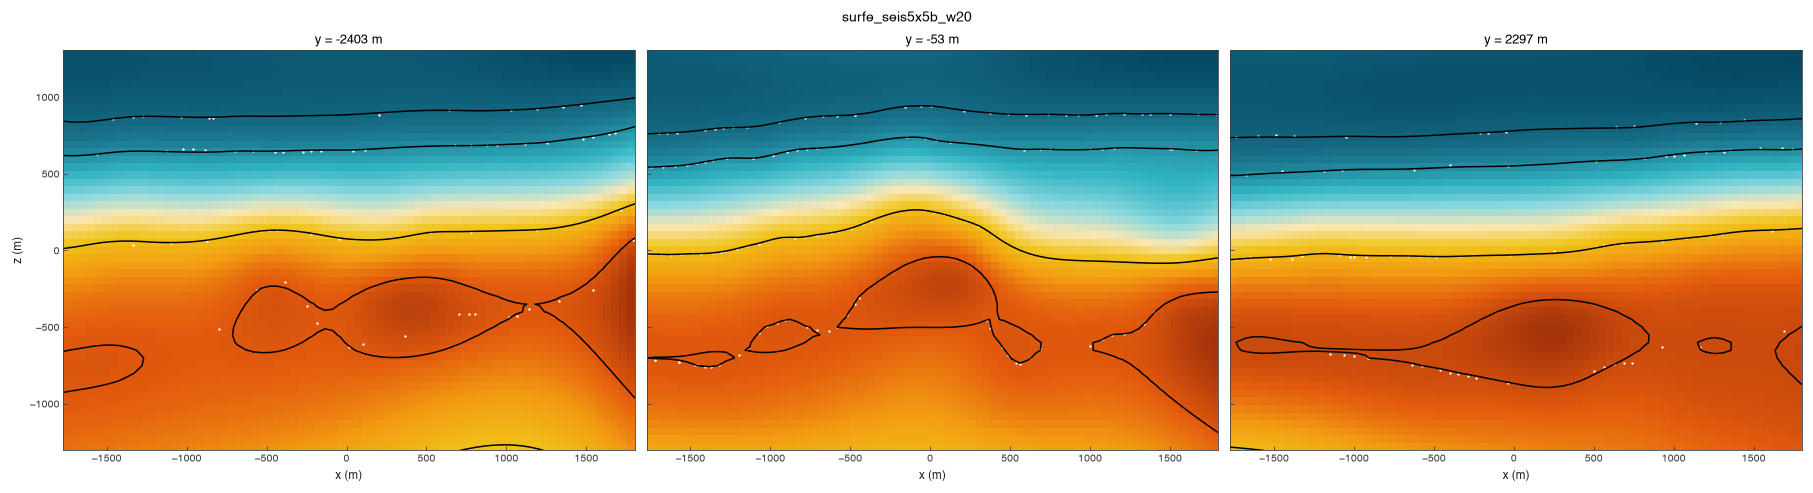

In [7]:
# Quick check (not saved): the scalar on three x-z sections, the model's contacts (black)
# and the contacts within 50 m of each section (white).
from contourpy import contour_generator

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True, sharey=True)
for ax, j in zip(axs, np.linspace(5, len(y) - 6, 3).astype(int)):
    sec = phi[:, j, :]
    ax.imshow(sec.T, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap=figstyle.ramp(), aspect="auto")
    gen = contour_generator(x=x, y=z, z=sec.T)
    for level in isovalues:
        for l in gen.lines(float(level)):
            ax.plot(*l.T, color="k", lw=0.9)
    for p in (*horizons, *held_out):
        near = np.abs(p[:, 1] - y[j]) < 10
        ax.scatter(p[near, 0], p[near, 2], s=2, color="w", linewidths=0)
    ax.set(title=f"y = {y[j]:.0f} m", xlabel="x (m)")
axs[0].set_ylabel("z (m)")
fig.suptitle(TAG)
plt.show()

## Isosurfaces

The four horizon surfaces, by marching cubes on a regular grid (scikit-image) over the box,
and the small closed level surface just inside each interior extremum (finer step), for the
figure's enclosures.

In [8]:
STEP = 50.0                                    # m, marching-cubes spacing of the surfaces
SHELL_STEP = 20.0                              # m, and of the small shells round extrema
SHELL_DELTA = 0.08                             # shell level, as a fraction of the level spacing
SHELL_HALF = 300.0                             # m, a shell must close within this distance of its extremum
coarse = diagnostics.surfe_mesher(model, STEP)
fine = diagnostics.surfe_mesher(model, SHELL_STEP)
mesher = lambda level, bounds: (coarse if np.ptp(bounds, axis=0).max() > 2 * SHELL_HALF else fine)(level, bounds)

extrema = [(p, kind, float(diagnostics.surfe_scalar(model, p[None])[0]))
           for kind in ("maximum", "minimum") for p in critical.of_kind(kind)]
spacing = float(np.min(np.abs(np.diff(isovalues))))
diagnostics.export_meshes(OUT_DIR / f"meshes_{TAG}.npz", mesher, isovalues, box, extrema=extrema,
                          shell_delta=SHELL_DELTA * spacing, shell_half=SHELL_HALF)
print(f"wrote meshes_{TAG}.npz: {len(isovalues)} surfaces, {len(extrema)} extrema")

wrote meshes_surfe_seis5x5b_w20.npz: 4 surfaces, 23 extrema


## Save

In [9]:
np.savez_compressed(
    OUT_DIR / f"{TAG}.npz",
    phi=phi.astype(np.float32), isovalues=isovalues, younging_angle=younging,
    **{f"distance_fit_{h}": d for h, d in enumerate(d_fit)},
    **{f"distance_held_out_{h}": d for h, d in enumerate(d_held)},
    **diagnostics.pack_critical(critical),
)
(OUT_DIR / f"{TAG}.json").write_text(json.dumps(
    {"comparison": comparison,
     "parameters": {"sampling": SAMPLING, "cutoff": CUTOFF, "lines": LINES if SAMPLING == "seismic" else None, "kernel": KERNEL, "poly_order": POLY_ORDER, "smoothing": SMOOTHING,
                    "interfaces": "one free equality per horizon (Lajaunie); labels only group points",
                    "fault": "not used"}}, indent=1))
print(f"wrote {TAG}.npz and {TAG}.json to", OUT_DIR)

wrote surfe_seis5x5b_w20.npz and surfe_seis5x5b_w20.json to results
